In [1]:
!pip install -q astroquery gala pyvo
!pip install numpy==2.2.6

from __future__ import annotations

from dataclasses import dataclass

from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks, peak_widths
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit

import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
import time, pyvo
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.gaia import Gaia
from gala.coordinates import GD1Koposov10
from tqdm.auto import tqdm
from astroquery.utils.tap.core import TapPlus

ARI = TapPlus(url="https://gaia.ari.uni-heidelberg.de/tap")
VIZIER = TapPlus(url="https://tapvizier.cds.unistra.fr/TAPVizieR/tap")
SVC = pyvo.dal.TAPService("https://gaia.aip.de/tap")




The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [2]:
"""
GD-1 stream candidate selection pipeline.

Sequence: query_gaia_region -> select_by_cmd -> select_by_proper_motion
-> select_by_footprint -> select_by_density -> fit_stream_track
-> find_underdensities -> bootstrap_member_count.

Thresholds are chosen from the data where possible."""


# -----------------------------------------------------------------------
# 1. Data acquisition
# -----------------------------------------------------------------------


Gaia.ROW_LIMIT = -1
USE_MIRROR = True
MAX_ROWS = 5000000


def clear_cache(cache_dir, pattern="*.pkl", dry_run=False):
    """Delete cached files in cache_dir (dry_run only lists them)."""
    cache_dir = Path(cache_dir)
    if not cache_dir.exists():
        print(f"{cache_dir} does not exist, nothing to clear")
        return
    files = sorted(cache_dir.glob(pattern))
    for f in files:
        print("removing" if not dry_run else "would remove", f.name)
        if not dry_run:
            f.unlink()
    print(f"{len(files)} file(s) {'found' if dry_run else 'removed'} in {cache_dir}")


def clear_gd1_cache(dry_run=False):
    clear_cache("cache_gd1_polygon", dry_run=dry_run)


def clear_radec_cache(dry_run=False):
    clear_cache("cache_radec_tiles", dry_run=dry_run)

def gd1_polygon(phi1_lo, phi1_hi, pad=4.0, n=12, phi2_center=0.0):
    """ICRS polygon covering phi1 in [lo, hi], |phi2 - phi2_center| < pad."""
    p1 = np.linspace(phi1_lo, phi1_hi, n)
    phi1 = np.concatenate([p1, p1[::-1]])
    phi2 = np.concatenate([np.full(n, phi2_center - pad), np.full(n, phi2_center + pad)])
    c = SkyCoord(phi1=phi1*u.deg, phi2=phi2*u.deg, frame=GD1Koposov10()).icrs
    return ", ".join(f"{a:.5f}, {d:.5f}" for a, d in zip(c.ra.deg, c.dec.deg))



_print_lock = threading.Lock()
def _log(*a):
    with _print_lock:
        print(*a, flush=True)


def run_query(q, use_sync=False, timeout=1800, poll=10, verbose=False):
    if use_sync:
        return SVC.run_sync(q).to_table().to_pandas()
    job = SVC.submit_job(q)
    job.run()
    t0 = time.time()
    while True:
        ph = job.phase
        if verbose:
            _log(f"{time.time()-t0:6.0f}s  {ph}")
        if ph in ("COMPLETED", "ERROR", "ABORTED"):
            break
        if time.time() - t0 > timeout:
            job.abort()
            raise TimeoutError("job timed out")
        time.sleep(poll)
    if ph != "COMPLETED":
        try:
            job.raise_if_error()
        except Exception as e:
            raise RuntimeError(f"job ended in phase {ph}: {e}") from None
    return job.fetch_result().to_table().to_pandas()


def _run_with_retry(query, retries=3):
    for attempt in range(retries):
        try:
            return run_query(query)
        except RuntimeError:
            raise
        except Exception as e:
            _log(f"  attempt {attempt+1} failed: {e}")
            time.sleep(2 ** attempt)
    raise RuntimeError("query failed after retries")


def _fetch(lo, hi, pad, phi2_center, min_width=0.5):
    query = f"""
    SELECT source_id, ra, dec, pmra, pmdec, parallax,
           pmra_error, pmdec_error, parallax_error,
           phot_g_mean_mag AS g, bp_rp, ruwe
    FROM gaiadr3.gaia_source
    WHERE CONTAINS(POINT('ICRS', ra, dec),
                   POLYGON('ICRS', {gd1_polygon(lo, hi, pad, phi2_center=phi2_center)})) = 1
        AND phot_g_mean_mag BETWEEN 14 AND 20.5
        AND ruwe < 1.4
        AND parallax < 1
        AND pmra IS NOT NULL AND pmdec IS NOT NULL
        AND pmra*pmra + pmdec*pmdec > 9
        AND pmra*pmra + pmdec*pmdec < 400
        AND parallax < 0.5 + 2*parallax_error
    """
    df = _run_with_retry(query)
    if len(df) >= MAX_ROWS:
        if (hi - lo) > min_width:
            mid = (lo + hi) / 2
            _log(f"  [{lo},{hi}] hit {MAX_ROWS} rows -> splitting at {mid}")
            return pd.concat([_fetch(lo, mid, pad, phi2_center, min_width),
                              _fetch(mid, hi, pad, phi2_center, min_width)],
                             ignore_index=True)
        raise RuntimeError(f"[{lo},{hi}] still truncated at min width; tighten the cuts")
    return df


def _fetch_chunk(lo, hi, pad, phi2_center, tag, cache_dir):
    """Load one chunk from cache, or fetch and cache it."""
    chunk_file = cache_dir / f"chunk_{lo}_{hi}_{tag}.pkl"
    if chunk_file.exists():
        return pd.read_pickle(chunk_file)
    df = _fetch(lo, hi, pad, phi2_center)
    tmp = chunk_file.with_suffix(".tmp")
    df.to_pickle(tmp)
    tmp.replace(chunk_file)
    _log(f"phi1 [{lo},{hi}] {tag}: {len(df)} rows")
    return df


def query_gaia_region(phi1_edges=tuple(range(-70, 6, 5)), pad=2.5,
                      phi2_center=0.0, cache_dir="cache_gd1_polygon",
                      n_workers=3):
    cache_dir = Path(cache_dir); cache_dir.mkdir(exist_ok=True)
    tag = f"gd1_phi2_{phi2_center:+.0f}_pad{pad}"
    final = cache_dir / f"Data_{tag}.pkl"

    if final.exists():
        return pd.read_pickle(final)

    bounds = list(zip(phi1_edges[:-1], phi1_edges[1:]))
    results = {}

    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        futs = {ex.submit(_fetch_chunk, lo, hi, pad, phi2_center, tag, cache_dir): (lo, hi)
                for lo, hi in bounds}
        try:
            for f in tqdm(as_completed(futs), total=len(futs)):
                results[futs[f]] = f.result()
        except BaseException:
            for f in futs:
                f.cancel()
            raise

    tables = [results[b] for b in bounds]
    data = pd.concat(tables, ignore_index=True).drop_duplicates("source_id")
    data.to_pickle(final)
    return data


def _fetch_ra_dec(ra_lo, ra_hi, dec_lo, dec_hi, min_width=0.25):
    """Fetch one RA/Dec box; bisect and recurse if the row cap is hit."""

    ra_c, dec_c = (ra_lo + ra_hi) / 2, (dec_lo + dec_hi) / 2
    w, h = ra_hi - ra_lo, dec_hi - dec_lo

    query= f"""
    SELECT source_id, ra, dec, pmra, pmdec, parallax,
           pmra_error, pmdec_error, parallax_error,
           phot_g_mean_mag AS g, bp_rp, ruwe
    FROM gaiadr3.gaia_source
    WHERE 1 = CONTAINS(POINT('ICRS', ra, dec),
                       BOX('ICRS', {ra_c}, {dec_c}, {w}, {h}))
        AND phot_g_mean_mag BETWEEN 14 AND 20.5
        AND ruwe < 1.4
        AND parallax < 1
        AND pmra IS NOT NULL AND pmdec IS NOT NULL
        AND pmra*pmra + pmdec*pmdec > 9
        AND pmra*pmra + pmdec*pmdec < 400
        AND parallax < 0.5 + 2*parallax_error
      """

    df = _run_with_retry(query)
    if len(df) < MAX_ROWS:
        return df

    d_ra, d_dec = ra_hi - ra_lo, dec_hi - dec_lo
    if max(d_ra, d_dec) <= min_width:
        raise RuntimeError(f"box RA[{ra_lo},{ra_hi}) Dec[{dec_lo},{dec_hi}) still "
                           f"truncated at min width; tighten the cuts")
    if d_ra >= d_dec:
        mid = (ra_lo + ra_hi) / 2
        print(f"  RA[{ra_lo},{ra_hi}) Dec[{dec_lo},{dec_hi}) hit cap -> split RA at {mid}")
        parts = [_fetch_ra_dec(ra_lo, mid, dec_lo, dec_hi, min_width),
                 _fetch_ra_dec(mid, ra_hi, dec_lo, dec_hi, min_width)]
    else:
        mid = (dec_lo + dec_hi) / 2
        print(f"  RA[{ra_lo},{ra_hi}) Dec[{dec_lo},{dec_hi}) hit cap -> split Dec at {mid}")
        parts = [_fetch_ra_dec(ra_lo, ra_hi, dec_lo, mid, min_width),
                 _fetch_ra_dec(ra_lo, ra_hi, mid, dec_hi, min_width)]
    return pd.concat(parts, ignore_index=True)


def query_gaia_region_ra_dec(ra_edges=tuple(range(120, 221, 10)),
                      dec_edges=tuple(range(20, 71, 10)),
                      cache_dir="cache_radec_tiles"):
    """Tile RA 120-220, Dec 20-70 in 10 deg steps (50 tiles), cached per tile and merged."""
    cache_dir = Path(cache_dir); cache_dir.mkdir(exist_ok=True)
    tag = f"radec_ra{ra_edges[0]}-{ra_edges[-1]}_dec{dec_edges[0]}-{dec_edges[-1]}"
    final = cache_dir / f"Data_{tag}.pkl"
    if final.exists():
        return pd.read_pickle(final)

    tiles = [(r0, r1, d0, d1)
             for r0, r1 in zip(ra_edges[:-1], ra_edges[1:])
             for d0, d1 in zip(dec_edges[:-1], dec_edges[1:])]

    def _load_tile(args):
        r0, r1, d0, d1 = args
        chunk_file = cache_dir / f"chunk_{tag}_ra{r0}_{r1}_dec{d0}_{d1}.pkl"
        if chunk_file.exists():
            return pd.read_pickle(chunk_file)
        df = _fetch_ra_dec(r0, r1, d0, d1)
        df.to_pickle(chunk_file)
        print(f"RA[{r0},{r1}) Dec[{d0},{d1}): {len(df):,} rows")
        return df

    with ThreadPoolExecutor(max_workers=5) as ex:
        tables = list(tqdm(ex.map(_load_tile, tiles), total=len(tiles)))

    result = pd.concat(tables, ignore_index=True)
    result = result.drop_duplicates("source_id").reset_index(drop=True)
    result.to_pickle(final)
    return result


# -----------------------------------------------------------------------
# 2. CMD / isochrone selection
# -----------------------------------------------------------------------

def load_isochrone(path: str | None=None, distance_modulus: float = 14.6) -> pd.DataFrame:
    """Return the GD-1 isochrone (apparent G, d ~ 8 kpc, no extinction), G > 18 only."""

    isochrone = {           # apparent G mag
    "g": [
20.362, 20.298, 20.185, 20.086, 19.989,
19.874, 19.865, 19.776, 19.667, 19.561, 19.456, 19.360, 19.313,
19.199, 19.085, 18.965, 18.855, 18.739, 18.613, 18.557, 18.533,
18.359, 18.231, 18.102, 17.986, 17.938, 17.797, 17.684, 17.658,
17.627, 17.513, 17.408, 17.308, 17.214, 17.124, 17.035, 16.940,
16.827, 16.720, 16.641, 16.563, 16.456, 16.343, 16.230, 16.101,
15.986, 15.860, 15.725, 15.606, 15.482, 15.360, 15.240, 15.122
],

    "bp_rp": [
0.909, 0.893, 0.865, 0.838, 0.814,
0.785, 0.783, 0.763, 0.741, 0.720, 0.701, 0.683, 0.675,
0.658, 0.641, 0.625, 0.612, 0.600, 0.588, 0.583, 0.580,
0.567, 0.559, 0.553, 0.550, 0.551, 0.557, 0.566, 0.569,
0.574, 0.595, 0.620, 0.651, 0.685, 0.719, 0.749, 0.777,
0.801, 0.818, 0.828, 0.834, 0.843, 0.850, 0.856, 0.863,
0.868, 0.874, 0.880, 0.886, 0.892, 0.898, 0.903, 0.909
]
}

    iso = pd.DataFrame(isochrone)
    iso=iso[iso["g"]>18]   # keep only G > 18 (near the stream)
    return iso[["bp_rp", "g"]]


def select_by_cmd(
    df: pd.DataFrame,
    isochrone: pd.DataFrame,
    dist_threshold: float | None = None,
) -> tuple[pd.DataFrame, float]:
    """
    Keep stars within `dist_threshold` of the isochrone in (bp_rp, g).
    If None, the threshold is the knee of the retained-fraction curve.
    Returns (selected_df, threshold_used).
    """
    isochrone = isochrone[np.isfinite(isochrone["bp_rp"]) & np.isfinite(isochrone["g"])]
    df = df[np.isfinite(df["bp_rp"]) & np.isfinite(df["g"])]
    tree = cKDTree(np.column_stack([isochrone["bp_rp"], isochrone["g"]]))

    dist, _ = tree.query(np.column_stack([df["bp_rp"], df["g"]]), k=1)
    df = df.assign(iso_dist=dist)

    if dist_threshold is None:
        dist_threshold = _find_knee_threshold(dist)

    selected = df[df["iso_dist"] < dist_threshold].copy()
    return selected, dist_threshold


def _find_knee_threshold(dist: np.ndarray, n_grid: int = 200,
                         max_percentile: float = 30.0,
                         max_dist: float | None = None) -> float:
    """
    Max-distance-to-chord knee of the retained-fraction curve, searched only
    up to `max_dist` (mag) or the `max_percentile` of dist.
    """
    upper = max_dist if max_dist is not None else np.percentile(dist, max_percentile)
    thresholds = np.linspace(dist.min(), upper, n_grid)
    retained_frac = np.array([(dist < t).mean() for t in thresholds])

    x = (thresholds - thresholds.min()) / (thresholds.max() - thresholds.min())
    y = (retained_frac - retained_frac.min()) / (retained_frac.max() - retained_frac.min())

    p1, p2 = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
    line_vec = (p2 - p1) / np.linalg.norm(p2 - p1)
    pts = np.column_stack([x, y]) - p1
    proj = np.outer(pts @ line_vec, line_vec)
    d = np.linalg.norm(pts - proj, axis=1)

    return thresholds[np.argmax(d)]


# -----------------------------------------------------------------------
# 3. Proper motion selection
# -----------------------------------------------------------------------

def select_by_proper_motion(
    df: pd.DataFrame,
    pm_phi1_range: tuple[float, float] = (-14, -8),
    pm_phi2_range: tuple[float, float] = (-4.5, -2.2),
) -> pd.DataFrame:
    """
    Transform to the GD1Koposov10 frame and cut on proper motion.
    """
    c = SkyCoord(
        ra=df["ra"].values * u.deg,
        dec=df["dec"].values * u.deg,
        pm_ra_cosdec=df["pmra"].values * u.mas / u.yr,
        pm_dec=df["pmdec"].values * u.mas / u.yr,
    )
    gd1 = c.transform_to(GD1Koposov10())

    out = df.copy()
    out["phi1"]    = gd1.phi1.deg
    out["phi2"]    = gd1.phi2.deg
    out["pm_phi1"] = gd1.pm_phi1_cosphi2.to_value(u.mas / u.yr)
    out["pm_phi2"] = gd1.pm_phi2.to_value(u.mas / u.yr)

    mask = out["pm_phi1"].between(*pm_phi1_range) & out["pm_phi2"].between(*pm_phi2_range)
    return out[mask].copy()


# -----------------------------------------------------------------------
# 4. Spatial footprint selection
# -----------------------------------------------------------------------

def select_by_footprint(
    df: pd.DataFrame,
    phi1_range: tuple[float, float] = (-70, 10),
    phi2_range: tuple[float, float] = (-1.5, 1),
) -> pd.DataFrame:
    """Restrict to the GD-1 footprint in stream coordinates."""
    mask = df["phi1"].between(*phi1_range) & df["phi2"].between(*phi2_range)
    return df[mask].copy()


# -----------------------------------------------------------------------
# 5. KDE density-contour selection
# -----------------------------------------------------------------------

def select_by_density(
    df: pd.DataFrame,
    background_df: pd.DataFrame | None = None,
    bandwidth: float | str = "silverman",
    background_multiple: float = 2.5,
) -> tuple[pd.DataFrame, dict]:
    """
    2D KDE over (phi1, phi2), thresholded at `background_multiple` x the
    background density (from `background_df`, else the 10th percentile of df).
    Returns (selected_df, diagnostics).
    """

    if len(df) < 10:
        return df.copy(), {}

    x, y = df["phi1"].values, df["phi2"].values
    kde = gaussian_kde(np.vstack([x, y]), bw_method=bandwidth)
    density_at_points = kde(np.vstack([x, y]))

    if background_df is not None and len(background_df) > 0:
        bx, by = background_df["phi1"].values, background_df["phi2"].values
        background_density = np.median(kde(np.vstack([bx, by])))
    else:
        background_density = np.percentile(density_at_points, 10)

    threshold = background_multiple * background_density
    mask = density_at_points > threshold

    # density grid for the diagnostic plot
    xe = np.linspace(x.min(), x.max(), 301)
    ye = np.linspace(y.min(), y.max(), 41)
    xc, yc = 0.5 * (xe[:-1] + xe[1:]), 0.5 * (ye[:-1] + ye[1:])
    gx, gy = np.meshgrid(xc, yc, indexing="ij")
    dens_map = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)  # (nx, ny)

    diagnostics = {
        "bandwidth_used": bandwidth,
        "background_density": background_density,
        "threshold": threshold,
        "x_edges": xe,
        "y_edges": ye,
        "map": dens_map,
    }
    return df[mask].copy(), diagnostics


# -----------------------------------------------------------------------
# 6. Track fit + width determination
# -----------------------------------------------------------------------

def _gauss_c(x, amp, mu, sigma, c=0.0):
    """Gaussian + constant."""
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + c


def fit_stream_track(
    df: pd.DataFrame,
    bin_width: float = 1.0,
    poly_order: int = 2,
    min_points_per_bin: int = 5,
) -> dict:
    """
    Fit a polynomial track phi2(phi1) to binned medians, then measure the
    width from a Gaussian fit to the residuals (reports 2σ and 3σ widths).
    """
    bins = np.arange(df["phi1"].min(), df["phi1"].max(), bin_width)
    centres, phi2_med = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = df["phi1"].between(lo, hi)
        if m.sum() > min_points_per_bin:
            centres.append((lo + hi) / 2)
            phi2_med.append(df.loc[m, "phi2"].median())
    centres, phi2_med = np.array(centres), np.array(phi2_med)

    coef = np.polyfit(centres, phi2_med, poly_order)
    poly = np.poly1d(coef)

    residuals = df["phi2"].values - poly(df["phi1"].values)

    hist, edges = np.histogram(residuals, bins=50, density=True)
    centers_h = 0.5 * (edges[:-1] + edges[1:])
    p0 = [hist.max(), 0.0, 0.3, hist.min()]
    popt, _ = curve_fit(_gauss_c, centers_h, hist, p0=p0,
                        bounds=([0, -2, 0.01, 0], [np.inf, 2, 3, np.inf]))
    _, mu_fit, sigma_fit, _ = popt

    return {
        "poly": poly,
        "poly_coef": coef,
        "residuals": residuals,
        "popt": popt,
        "centres": centres,
        "phi2_med": phi2_med,
        "residual_sigma": abs(sigma_fit),
        "residual_mu": mu_fit,
        "suggested_width_2sigma": 2 * abs(sigma_fit),
        "suggested_width_3sigma": 3 * abs(sigma_fit),
    }

def select_by_track_width(df: pd.DataFrame, poly: np.poly1d, width: float, return_all = True) -> pd.DataFrame:
    """Apply the measured perpendicular width cut (return_all=True skips the cut)."""
    predicted = poly(df["phi1"])
    mask = np.abs(df["phi2"] - predicted) < width
    if return_all:
        return df.copy()
    return df[mask].copy()


# -----------------------------------------------------------------------
# 7. Underdensity (gap) detection
# -----------------------------------------------------------------------

def _phi1_bounds(phi1, exclude_first_pct, exclude_last_pct) -> tuple[lo, hi]:
    """Exclude the first and last `exclude_first_pct` and `exclude_last_pct` of phi1."""
    span = phi1.max() - phi1.min()
    lo = phi1.min() + exclude_first_pct / 100 * span
    hi = phi1.max() - exclude_last_pct / 100 * span
    return lo, hi


def find_underdensities(
    stream_df,
    bin_width=0.5,
    smoothing_sigmas=(1.0, 2.0, 3.0),   # in bins
    baseline_poly_order=3,
    min_significance=2.0,
    n_clip_iter=6,
    merge_tol=1.0,                      # deg: closer detections are merged
    exclude_first_pct=5.0,              # first % of phi1 extent ignored in detection
    exclude_last_pct=5.0,               # last % of phi1 extent ignored in detection
    return_diagnostics=False,
) -> pd.DataFrame:
    """Find Underdensities based on devaiation of sigma from sigma=0"""
    phi = stream_df["phi1"].values
    edges = np.arange(phi.min(), phi.max() + bin_width, bin_width)
    counts, edges = np.histogram(phi, bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])

    lo, hi = _phi1_bounds(phi, exclude_first_pct, exclude_last_pct)
    use = (centers >= lo) & (centers <= hi)

    # robust baseline via iterative sigma clipping, fitted on `use` bins only
    keep = use.copy()
    for _ in range(n_clip_iter):
        coef = np.polyfit(centers[keep], counts[keep], baseline_poly_order)
        base = np.clip(np.polyval(coef, centers), 1e-3, None)
        keep = (np.abs(counts - base) < 2.5 * np.sqrt(base)) & use

    rows, diag = [], {}
    for s in smoothing_sigmas:
        smooth = gaussian_filter1d(counts.astype(float), s, mode="nearest")
        residual = smooth - base
        noise = np.sqrt(base / (2 * np.sqrt(np.pi) * s))
        signif = -residual / noise
        signif[~use] = 0.0                  # no detections in the excluded region

        padded = np.r_[signif[0] - 1, signif, signif[-1] - 1]
        idx, _ = find_peaks(padded, height=min_significance, prominence=1.0)
        idx = idx - 1
        if len(idx):
            widths = peak_widths(padded, idx + 1, rel_height=0.5)[0]
            for i, w in zip(idx, widths):
                half = 0.5 * w * bin_width
                rows.append(dict(
                    phi1_center=centers[i],
                    depth_frac=residual[i] / base[i],
                    width=w * bin_width,
                    phi1_start=max(centers[i] - half, lo),   # clipped to analysis window
                    phi1_end=min(centers[i] + half, hi),
                    significance_sigma=signif[i],
                    smoothing_sigma=s,
                ))
        diag[s] = dict(smooth=smooth, signif=signif)

    cols = ["phi1_center", "depth_frac", "width", "phi1_start", "phi1_end",
            "significance_sigma", "smoothing_sigma"]
    if not rows:
        gaps = pd.DataFrame(columns=cols)
    else:
        cand = pd.DataFrame(rows).sort_values("significance_sigma", ascending=False)
        kept = []
        for _, r in cand.iterrows():
            if all(abs(r.phi1_center - k.phi1_center) > merge_tol for k in kept):
                kept.append(r)
        gaps = (pd.DataFrame(kept).sort_values("phi1_center")
                .reset_index(drop=True))

    if return_diagnostics:
        return gaps, dict(centers=centers, counts=counts, base=base,
                          per_scale=diag, use=use)
    return gaps

# -----------------------------------------------------------------------
# 8. Uncertainty quantification
# -----------------------------------------------------------------------

GAP_TABLE_COLS = ["phi1_center", "depth_frac", "width", "phi1_start", "phi1_end",
                  "significance_sigma", "smoothing_sigma", "iteration"]

def mc_member_count(raw_df, pipeline_fn, n_iterations=100,
                    perturb_astrometry=True, rng_seed=42,
                    background_multiple=2.5, gap_fn=None,
                    min_members=20, verbose=True ):
    """
    Monte Carlo over proper-motion errors. Each iteration perturbs pmra/pmdec by
    draws from their Gaia errors, reruns the selection, and records the member
    count (and detected gaps if gap_fn is given). The spread measures the
    sensitivity of the selection to PM measurement uncertainty.
    """
    rng = np.random.default_rng(rng_seed)
    counts, gap_tables, n_failed = [], [], 0
    for k in range(n_iterations):
        if perturb_astrometry:
            trial = raw_df.copy()
            trial["pmra"] += rng.normal(0, raw_df["pmra_error"])
            trial["pmdec"] += rng.normal(0, raw_df["pmdec_error"])
        else:
            trial = raw_df.sample(frac=1.0, replace=True,
                                  random_state=int(rng.integers(1_000_000_000)))

        result = pipeline_fn(trial, background_multiple=background_multiple)
        if len(result) < min_members:
            n_failed += 1
            continue
        counts.append(len(result))

        gaps_k = None
        if gap_fn is not None:
            gaps_k = gap_fn(result)
            if len(gaps_k):
                gap_tables.append(gaps_k.assign(iteration=k))

        if verbose:
            pm_n, fp_n, dens_n = result.attrs.get("stages", (np.nan,) * 3)
            line = f"PM: {pm_n} footprint: {fp_n} density: {dens_n}"
            if gaps_k is not None:
                desc = ", ".join(f"{g.phi1_center:.1f} ({g.significance_sigma:.1f}σ)"
                                 for g in gaps_k.itertuples())
                line += f" | underdensities: {len(gaps_k)}" + (f" [{desc}]" if desc else "")
            print(line)

    counts = np.array(counts)
    return {
        "counts": counts, "n_ok": len(counts), "n_failed": n_failed,
        "mean": counts.mean(), "std": counts.std(), "median": np.median(counts),
        "16th_pctile": np.percentile(counts, 16),
        "84th_pctile": np.percentile(counts, 84),
        "gaps": (pd.concat(gap_tables, ignore_index=True)
                 if gap_tables else pd.DataFrame(columns=GAP_TABLE_COLS)),
    }


def gap_recovery(nominal_gaps, mc, tol=None):
    """Fraction of successful realizations that recover each nominal gap."""
    out = []
    bg = mc["gaps"]
    for _, g in nominal_gaps.iterrows():
        t = tol if tol is not None else 0.5 * g["width"]
        hit = bg[(bg["phi1_center"] - g["phi1_center"]).abs() <= t]
        out.append(dict(
            phi1_center=g["phi1_center"],
            recovered_frac=hit["iteration"].nunique() / mc["n_ok"],
            center_scatter=hit["phi1_center"].std(),
            signif_median=hit["significance_sigma"].median(),
            signif_std=hit["significance_sigma"].std(),
        ))
    return pd.DataFrame(out)


# -----------------------------------------------------------------------
# 9. Orchestration (running all functions)
# -----------------------------------------------------------------------

@dataclass
class PipelineResult:
    n_initial: int
    n_after_cmd: int
    n_after_pm: int
    n_after_footprint: int
    n_after_density: int
    n_final: int
    track_fit: dict
    underdensities: pd.DataFrame
    member_count_uncertainty: dict


def run_pipeline(raw_df: pd.DataFrame, isochrone: pd.DataFrame) -> PipelineResult:
    """Run the full chain and return the count after every stage."""
    n_initial = len(raw_df)

    after_cmd, dist_thresh = select_by_cmd(raw_df, isochrone)
    after_pm = select_by_proper_motion(after_cmd)
    after_footprint = select_by_footprint(after_pm)
    after_density, density_diag = select_by_density(after_footprint)
    track_fit = fit_stream_track(after_density)
    final = select_by_track_width(after_density, track_fit["poly"], track_fit["suggested_width_2sigma"])

    underdensities = find_underdensities(final)

    return PipelineResult(
        n_initial=n_initial,
        n_after_cmd=len(after_cmd),
        n_after_pm=len(after_pm),
        n_after_footprint=len(after_footprint),
        n_after_density=len(after_density),
        n_final=len(final),
        track_fit=track_fit,
        underdensities=underdensities,
        member_count_uncertainty={},
    )


def apply_cuts(cmd_df, phi2_offset=0.0, fixed=None, background_multiple = 2.5, return_all = True, verbose = True):
    after_pm = select_by_proper_motion(cmd_df).copy()
    if phi2_offset:
        after_pm["phi2"] = after_pm["phi2"] - phi2_offset
    after_fp = select_by_footprint(after_pm)

    if fixed is None:
        after_density, density_diag = select_by_density(
            after_fp, background_multiple=background_multiple)
        track = fit_stream_track(after_density)
        width = track["suggested_width_2sigma"]
    else:
        after_density, density_diag = select_by_density(
            after_fp, background_multiple = background_multiple)
        track = fixed["track"]
        width = fixed["width"]

    final = select_by_track_width(after_density, track["poly"], width, return_all)

    if verbose:
        print("PM:", len(after_pm), "footprint:", len(after_fp), "density:", len(after_density))
    return dict(pm=after_pm, footprint=after_fp, density=after_density,
                density_diag=density_diag, track=track, final=final)


def _safe_final(df: pd.DataFrame, background_multiple = 2.5) -> pd.DataFrame:
    """For the Bootstrap; a failed iteration returns an empty frame."""
    try:
        out = apply_cuts(df, background_multiple=background_multiple, verbose=False)
        final = out["final"]
        final.attrs["stages"] = (len(out["pm"]), len(out["footprint"]), len(out["density"]))
        return final
    except Exception:
        return df.iloc[0:0]


# -----------------------------------------------------------------------
# 10. Plots
# -----------------------------------------------------------------------

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

def _finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()


def add_gd1_coords(df):
    """Add GD-1 frame coordinates and proper motions to any table."""
    c = SkyCoord(ra=df["ra"].values * u.deg, dec=df["dec"].values * u.deg,
                 pm_ra_cosdec=df["pmra"].values * u.mas / u.yr,
                 pm_dec=df["pmdec"].values * u.mas / u.yr)
    g = c.transform_to(GD1Koposov10())
    out = df.copy()
    out["phi1"], out["phi2"] = g.phi1.deg, g.phi2.deg
    out["pm_phi1"] = g.pm_phi1_cosphi2.to_value(u.mas / u.yr)
    out["pm_phi2"] = g.pm_phi2.to_value(u.mas / u.yr)
    return out


def plot_funnel(result):
    names = ["initial", "CMD", "PM", "footprint", "density", "final"]
    vals = [result.n_initial, result.n_after_cmd, result.n_after_pm,
            result.n_after_footprint, result.n_after_density, result.n_final]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(names[::-1], vals[::-1]); ax.set_xscale("log")
    for i, v in enumerate(vals[::-1]):
        ax.text(v, i, f" {v:,}", va="center")
    ax.set_xlabel("stars"); ax.set_title("Selection funnel")
    _finish(fig, "01_funnel")


def plot_cmd(raw, iso, after_cmd, dist_thresh):
    """Left: CMD with isochrone and selection. Right: knee curve."""
    tree = cKDTree(np.column_stack([iso["bp_rp"], iso["g"]]))
    dist, _ = tree.query(np.column_stack([raw["bp_rp"], raw["g"]]), k=1)
    thr = np.linspace(dist.min(), np.percentile(dist, 95), 200)
    frac = np.array([(dist < t).mean() for t in thr])

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].hist2d(raw["bp_rp"], raw["g"], bins=[120, 100],
                 range=[[-0.5, 2.5], [14, 21]], norm=LogNorm(), cmap="Greys")
    ax[0].scatter(after_cmd["bp_rp"], after_cmd["g"], s=1, c="tab:blue",
                  alpha=0.3, rasterized=True, label="CMD-selected")
    ax[0].plot(iso["bp_rp"], iso["g"], "r-", lw=2, label="isochrone")
    ax[0].invert_yaxis(); ax[0].set_xlabel("BP-RP"); ax[0].set_ylabel("G")
    ax[0].legend(); ax[0].set_title("CMD selection")

    ax[1].plot(thr, frac)
    ax[1].axvline(dist_thresh, c="r", ls="--", label=f"threshold = {dist_thresh:.3f}")
    ax[1].set_xlabel("distance to isochrone (mag)")
    ax[1].set_ylabel("retained fraction"); ax[1].legend()
    ax[1].set_title("Knee detection")
    _finish(fig, "02_cmd")


def plot_pm(after_cmd, box1=(-14, -8), box2=(-4.5, -2.2)):
    """On-stream vs area-scaled off-stream PM histograms, and their difference."""
    d = add_gd1_coords(after_cmd)
    on = d[d["phi2"].abs() < 0.5]
    off = d[(d["phi2"].abs() > 1.5) & (d["phi2"].abs() < 2.5)]
    rng = [[-18, 2], [-8, 4]]
    Hon, _, _ = np.histogram2d(on["pm_phi1"], on["pm_phi2"], bins=[40, 24], range=rng)
    Hoff, _, _ = np.histogram2d(off["pm_phi1"], off["pm_phi2"], bins=[40, 24], range=rng)
    Hoff = Hoff * 0.5      # on-stream strip 1 deg wide, off-stream 2 deg
    diff = Hon - Hoff
    ext = [rng[0][0], rng[0][1], rng[1][0], rng[1][1]]

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    for a, H, t, kw in zip(ax, [Hon, Hoff, diff],
                           ["on-stream (|phi2|<0.5)", "off-stream, area-scaled", "difference"],
                           [{}, {}, dict(cmap="RdBu_r", vmin=-abs(diff).max(), vmax=abs(diff).max())]):
        im = a.imshow(H.T, origin="lower", aspect="auto", extent=ext, **kw)
        a.add_patch(Rectangle((box1[0], box2[0]), box1[1] - box1[0], box2[1] - box2[0],
                              fill=False, ec="r", lw=2))
        a.set_xlabel("pm_phi1 (mas/yr)"); a.set_ylabel("pm_phi2 (mas/yr)")
        a.set_title(t); plt.colorbar(im, ax=a)
    _finish(fig, "03_proper_motion")


def plot_footprint(res):
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.scatter(res["pm"]["phi1"], res["pm"]["phi2"], s=1, c="lightgrey", label="after PM")
    ax.scatter(res["footprint"]["phi1"], res["footprint"]["phi2"], s=2, c="tab:blue",
               label="inside footprint")
    ax.add_patch(Rectangle((-70, -1.5), 75, 2.5, fill=False, ec="r", lw=2))
    ax.set_xlabel("phi1 (deg)"); ax.set_ylabel("phi2 (deg)"); ax.legend()
    ax.set_title("Footprint selection")
    _finish(fig, "04_footprint")


def plot_density(res):
    d = res["density_diag"]
    if not d:
        print("plot_density: density stage did not run"); return
    xe, ye = d["x_edges"], d["y_edges"]
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    im = ax[0].imshow(d["map"].T, origin="lower", aspect="auto",
                      extent=[xe[0], xe[-1], ye[0], ye[-1]])
    plt.colorbar(im, ax=ax[0], label="KDE density (per deg$^2$)")

    xc = 0.5 * (xe[:-1] + xe[1:]); yc = 0.5 * (ye[:-1] + ye[1:])
    ax[0].contour(xc, yc, d["map"].T, levels=[d["threshold"]], colors="w", linewidths=0.8)

    ax[0].set_title(f"Smoothed density map (background {d['background_density']:.3f}, "
                    f"threshold {d['threshold']:.3f})")
    ax[1].scatter(res["footprint"]["phi1"], res["footprint"]["phi2"], s=1, c="lightgrey")
    ax[1].scatter(res["density"]["phi1"], res["density"]["phi2"], s=6, c="tab:red",
                  label=f"kept ({len(res['density']):,})")
    ax[1].set_xlabel("phi1 (deg)"); ax[0].set_ylabel("phi2 (deg)")
    ax[1].set_ylabel("phi2 (deg)"); ax[1].legend()
    _finish(fig, "05_density")


def plot_track(res):
    t = res["track"]
    if t is None:
        print("plot_track: track fit did not run"); return
    dens, final = res["density"], res["final"]
    x = np.linspace(dens["phi1"].min(), dens["phi1"].max(), 300)
    w = t["suggested_width_2sigma"]

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
    ax[0].scatter(dens["phi1"], dens["phi2"], s=6, c="lightgrey", label="after density")
    ax[0].scatter(final["phi1"], final["phi2"], s=8, c="tab:red", label="final")
    ax[0].plot(x, t["poly"](x), "k-", label="track")
    ax[0].fill_between(x, t["poly"](x) - w, t["poly"](x) + w, color="k", alpha=0.15,
                       label="±2σ")
    ax[0].set_xlabel("phi1 (deg)"); ax[0].set_ylabel("phi2 (deg)"); ax[0].legend()

    h, e = np.histogram(t["residuals"], bins=50, density=True)
    c = 0.5 * (e[1:] + e[:-1]); xx = np.linspace(e[0], e[-1], 300)
    ax[1].bar(c, h, width=np.diff(e), alpha=0.5)
    ax[1].plot(xx, _gauss_c(xx, *t["popt"]), "r-")
    for s in (-w, w):
        ax[1].axvline(s, c="k", ls="--")
    ax[1].set_xlabel("phi2 - track (deg)")
    ax[1].set_title(f"σ = {t['residual_sigma']:.3f} deg")
    _finish(fig, "06_track_width")


def plot_gaps(final, gaps, min_significance=2.0, bin_width=0.5,
              smoothing_sigma=2.0, baseline_poly_order=3, n_clip_iter=6,
              exclude_first_pct=5.0, exclude_last_pct=5.0, sigma=None):
    phi = final["phi1"].values
    edges = np.arange(phi.min(), phi.max() + bin_width, bin_width)
    counts, edges = np.histogram(phi, bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])

    lo, hi = _phi1_bounds(phi, exclude_first_pct, exclude_last_pct)
    use = (centers >= lo) & (centers <= hi)

    keep = use.copy()
    for _ in range(n_clip_iter):
        coef = np.polyfit(centers[keep], counts[keep], baseline_poly_order)
        baseline = np.clip(np.polyval(coef, centers), 1e-3, None)
        keep = (np.abs(counts - baseline) < 2.5 * np.sqrt(baseline)) & use

    smooth = gaussian_filter1d(counts.astype(float), smoothing_sigma, mode="nearest")
    resid = smooth - baseline

    # Poisson noise on the smoothed profile: baseline / (2*sqrt(pi)*s)
    if sigma is None:
        sigma = np.sqrt(baseline / (2 * np.sqrt(np.pi) * smoothing_sigma))
    thresh = -min_significance * sigma

    fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax[0].step(centers, counts, where="mid", c="grey", label=f"counts / {bin_width} deg")
    ax[0].plot(centers, smooth, label="smoothed")
    ax[0].plot(centers, baseline, "k--", label="baseline")
    ax[0].plot(centers, baseline + thresh, c="tab:red", ls=":",
               label=f"threshold ({min_significance:g}σ below baseline)")
    ax[0].set_ylabel("No. of stars")
    ax[0].legend()

    ax[1].plot(centers, resid)
    ax[1].axhline(0, c="k", lw=0.5)
    ax[1].plot(centers, thresh, c="tab:red", ls=":", label=f"-{min_significance:g}σ threshold")
    ax[1].legend()
    ax[1].set_xlabel("phi1 (deg)"); ax[1].set_ylabel("smoothed - baseline")

    for _, g in gaps.iterrows():
        for a in ax:
            a.axvspan(g["phi1_center"] - g["width"] / 2, g["phi1_center"] + g["width"] / 2,
                      color="tab:red", alpha=0.15)
    ax[0].set_title("Density along the stream (red = detected underdensities)")
    _finish(fig, "07_gaps")


def plot_mc(mc, n_nominal):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(mc["counts"], bins=20, alpha=0.6)
    ax.axvline(n_nominal, c="k", label=f"nominal N = {n_nominal}")
    ax.axvline(mc["median"], c="r", label=f"MC median = {mc['median']:.0f}")
    for q in ("16th_pctile", "84th_pctile"):
        ax.axvline(mc[q], c="r", ls="--")
    ax.set_xlabel("final member count"); ax.set_ylabel("realizations")
    ax.legend(); ax.set_title("Monte Carlo over PM errors")
    _finish(fig, "08_mc_pm_errors")


def make_diagnostic_plots(result, diag):
    res = diag["res"]
    plot_funnel(result)
    plot_cmd(diag["raw"], diag["iso"], diag["after_cmd"], diag["dist_thresh"])
    plot_pm(diag["after_cmd"])
    plot_footprint(res)
    plot_density(res)
    plot_track(res)
    if len(res["final"]) > 2:
        plot_gaps(res["final"], diag["gaps"], **diag["gap_kw"])
    plot_mc(diag["mc"], len(res["final"]))

  0%|          | 0/8 [00:00<?, ?it/s]

phi1 [-50,-40] gd1_phi2_+0_pad2.5: 42765 rows
phi1 [-60,-50] gd1_phi2_+0_pad2.5: 54213 rows
phi1 [-40,-30] gd1_phi2_+0_pad2.5: 36511 rows
phi1 [-70,-60] gd1_phi2_+0_pad2.5: 71877 rows
phi1 [-30,-20] gd1_phi2_+0_pad2.5: 34076 rows
phi1 [-20,-10] gd1_phi2_+0_pad2.5: 33200 rows
phi1 [-10,0] gd1_phi2_+0_pad2.5: 36948 rows
phi1 [0,10] gd1_phi2_+0_pad2.5: 44166 rows
[1] Raw stars: 351,935
[2] After CMD: 66,252 (iso-distance threshold 0.209)
PM: 3558 footprint: 2256 density: 775
[3] After PM:        3,558
[4] After footprint: 2,256
[5] After density:   775
[6] Final members:   775  (sigma = 0.182 deg, 2-sigma cut = 0.364 deg)
[7] Underdensities found: 2
 phi1_center  depth_frac  width  phi1_start  phi1_end  significance_sigma  smoothing_sigma
     -42.012      -0.243  8.486     -46.255   -37.769               2.266              3.0
     -20.012      -0.389  6.909     -23.467   -16.558               3.465              3.0
PM: 3464 footprint: 2182 density: 616 | underdensities: 2 [-41.8 (2.6σ),

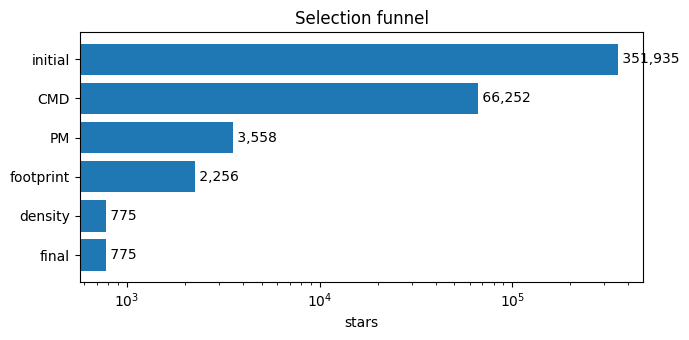

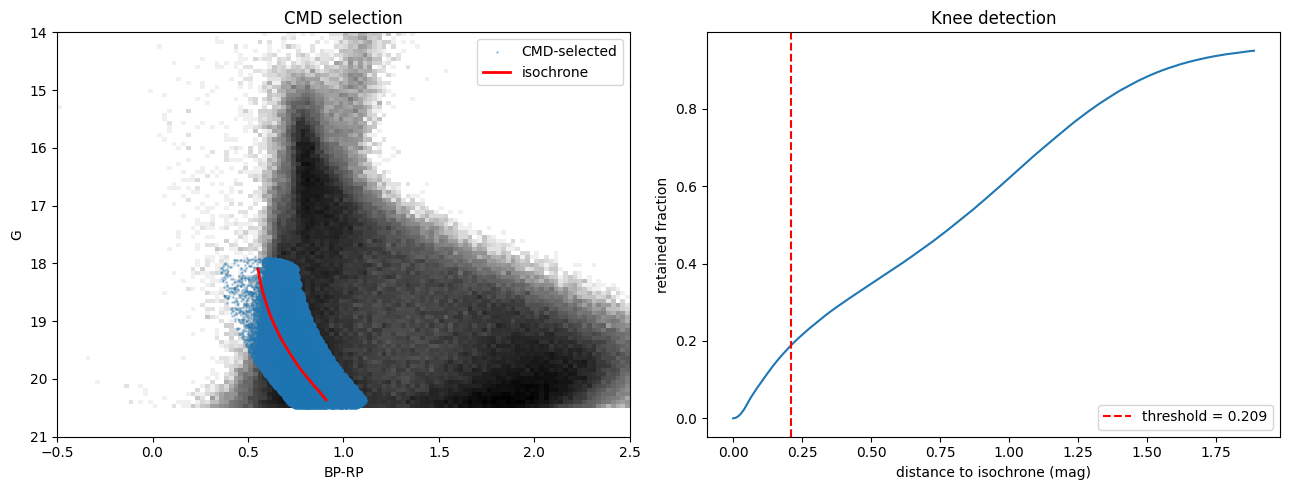

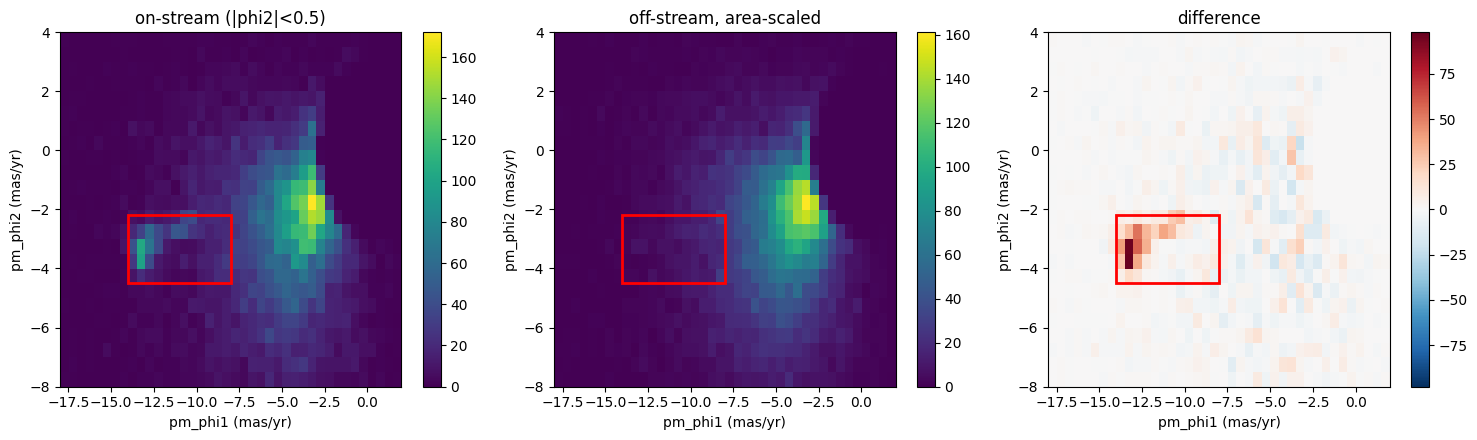

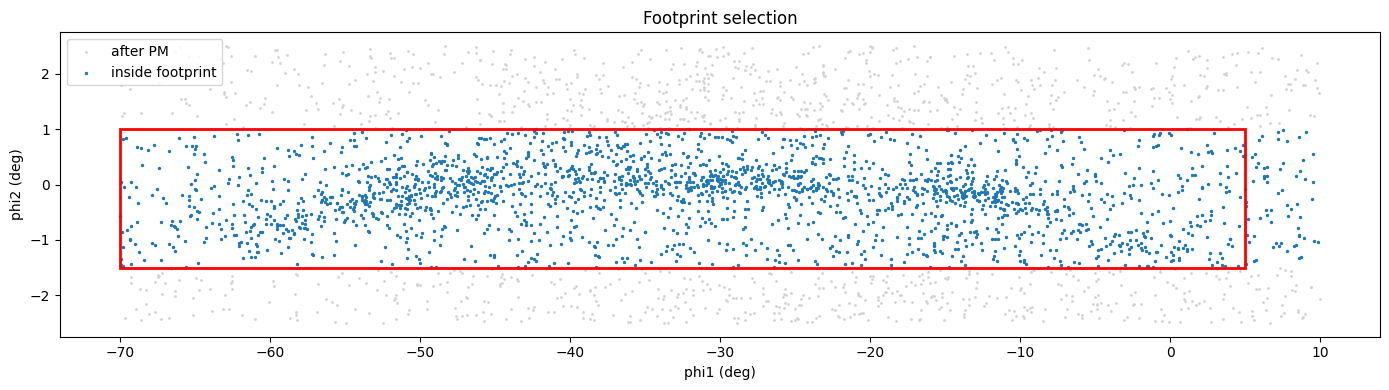

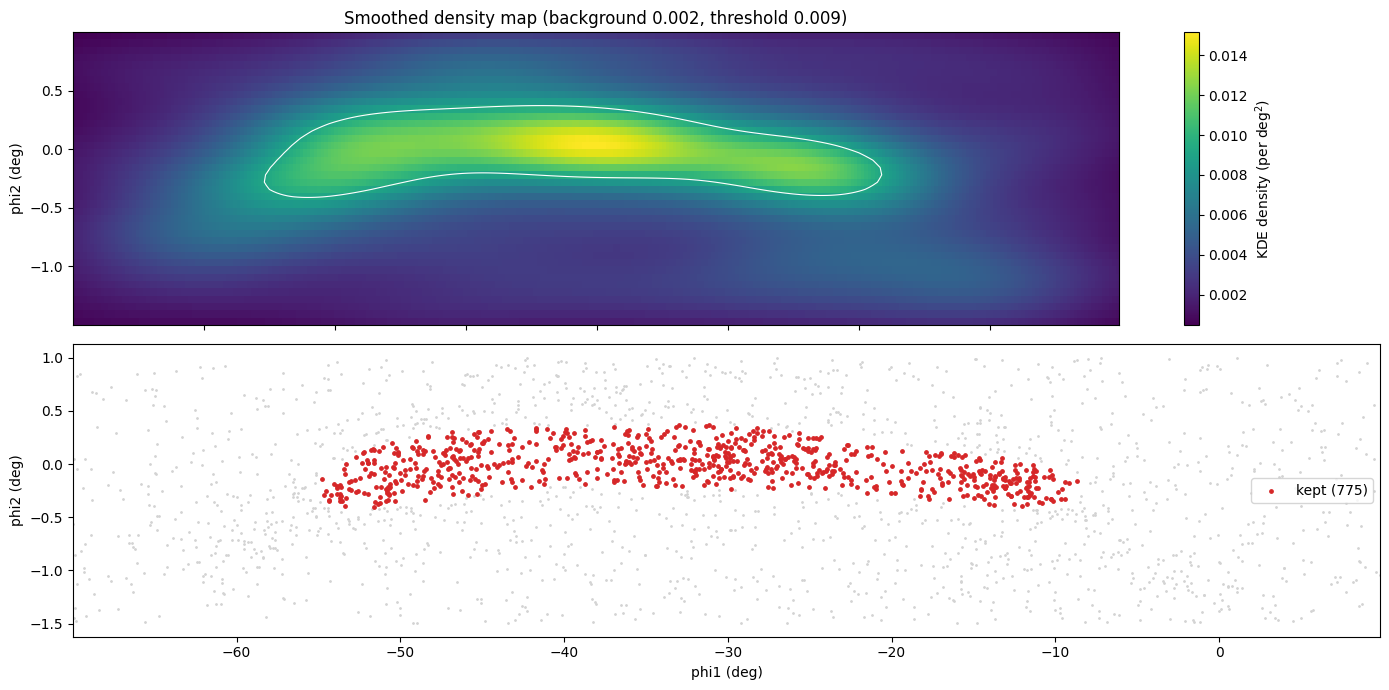

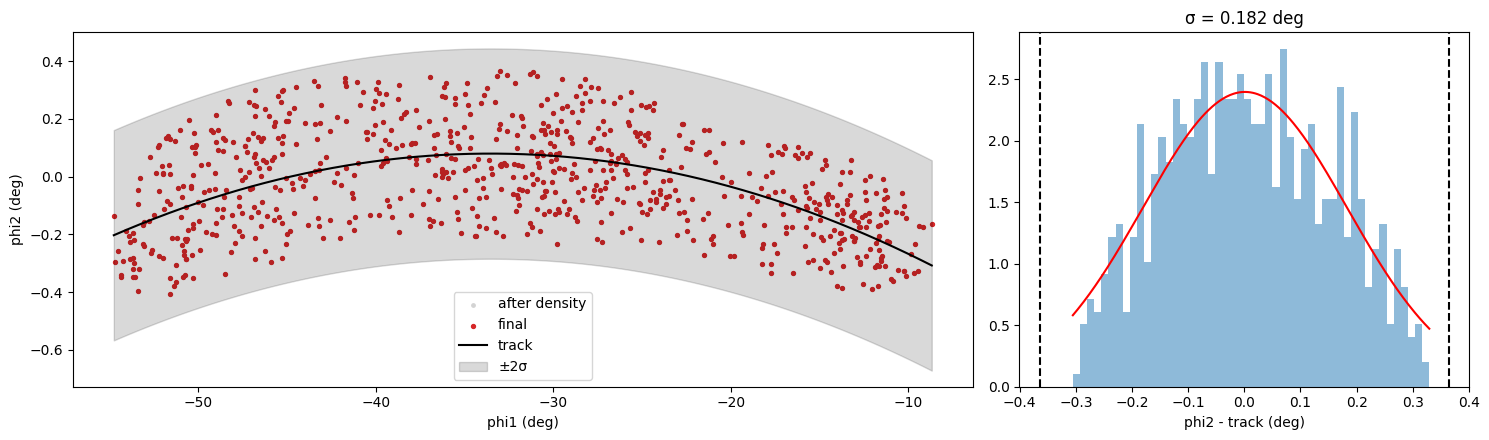

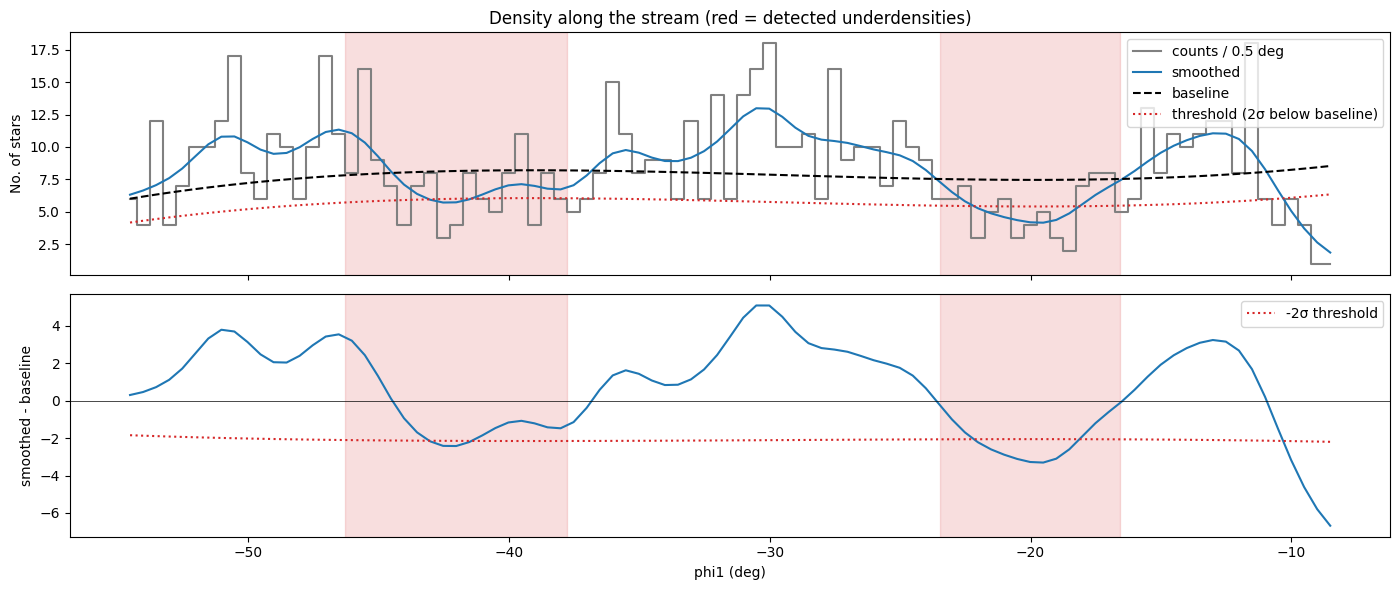

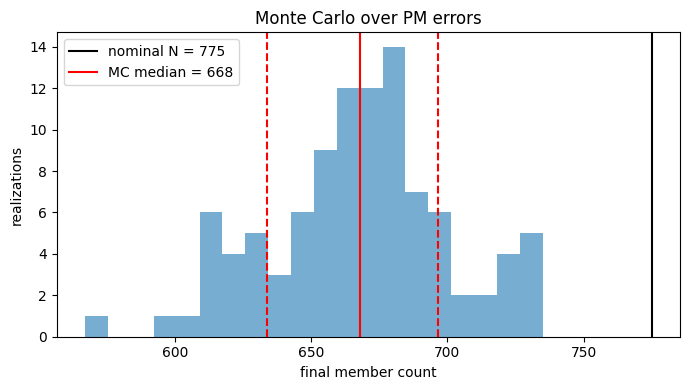

In [3]:
def main(isochrone_path: str | None = None,
         phi1_edges=tuple(range(-70, 11, 10)),
         pad: float = 2.5,
         n_mc: int = 100,
         min_significance = 2,
         background_multiple = 4,
         exclude_first_pct = 10.0,
         exclude_last_pct = 10.0,
         return_all = True,
         out_dir: str = "results"):
    """
    Analysing only the relevant portions near the stream in stream coordinates (phi1, phi2).

    Instead of tiling the sky in RA/Dec, the data are split into segments
    along the stream (phi1). Each segment is isochrone-filtered and its signal
    is measured against a background estimated from the surrounding region,
    to find its underdensities and their widths. We then run a Monte Carlo over
    the Gaia proper-motion errors (re-perturbing pmra/pmdec and rerunning the
    selection) to see how stable the selected membership and the detected
    underdensities are.
    """

    out_dir = Path(out_dir); out_dir.mkdir(exist_ok=True)
    iso = load_isochrone(isochrone_path)

    # 1. Data (cached, chunked)
    raw = query_gaia_region(phi1_edges=phi1_edges, pad=pad)
    raw = raw.dropna(subset=["bp_rp", "g"])
    print(f"[1] Raw stars: {len(raw):,}")

    # 2. CMD cut
    after_cmd, dist_thresh = select_by_cmd(raw, iso)
    print(f"[2] After CMD: {len(after_cmd):,} (iso-distance threshold {dist_thresh:.3f})")

    # 3-6. PM -> footprint -> density -> track width
    res = apply_cuts(after_cmd, background_multiple = background_multiple)
    final, t = res["final"], res["track"]
    print(f"[3] After PM:        {len(res["pm"]):,}")
    print(f"[4] After footprint: {len(res["footprint"]):,}")
    print(f"[5] After density:   {len(res["density"]):,}")
    print(f"[6] Final members:   {len(final):,}  "
            f"(sigma = {t["residual_sigma"]:.3f} deg, 2-sigma cut = {t["suggested_width_2sigma"]:.3f} deg)")

    # 7. Underdensities
    gap_kw = dict(min_significance=min_significance, bin_width=0.5,
                    exclude_first_pct=exclude_first_pct,
                    exclude_last_pct=exclude_last_pct)
    gaps = find_underdensities(final, **gap_kw)
    print(f"[7] Underdensities found: {len(gaps)}")
    if len(gaps):
        print(gaps.round(3).to_string(index=False))

    # 8. Monte Carlo over PM errors
    mc = mc_member_count(after_cmd, pipeline_fn=_safe_final,
                         background_multiple=background_multiple,
                         n_iterations=n_mc,
                         gap_fn=lambda f: find_underdensities(f, **gap_kw))
    print(f"[8] N = {mc['median']:.0f} "
          f"(+{mc['84th_pctile']-mc['median']:.0f} / -{mc['median']-mc['16th_pctile']:.0f}), "
          f"{mc['n_failed']} failed")
    rec = gap_recovery(gaps, mc)
    print(rec.round(3).to_string(index=False))

    result = PipelineResult(
        n_initial=len(raw), n_after_cmd=len(after_cmd),
        n_after_pm=len(res["pm"]), n_after_footprint=len(res["footprint"]),
        n_after_density=len(res["density"]), n_final=len(final),
        track_fit=t, underdensities=gaps,
        member_count_uncertainty=mc)

    final.to_pickle(out_dir / "gd1_members_polygon.pkl")
    gaps.to_csv(out_dir / "gd1_gaps_polygon.csv", index=False)

    diag = {
        "raw": raw,
        "iso": iso,
        "after_cmd": after_cmd,
        "dist_thresh": dist_thresh,
        "res": res,
        "gaps": gaps,
        "gap_kw": gap_kw,
        "mc": mc,
    }

    make_diagnostic_plots(result, diag)

    return result, final, diag


result, members, diag = main()

  0%|          | 0/25 [00:00<?, ?it/s]

RA[120,140) Dec[50,60): 129,781 rows
RA[120,140) Dec[60,70): 97,243 rows
RA[120,140) Dec[40,50): 163,456 rows
RA[120,140) Dec[30,40): 206,106 rows
RA[120,140) Dec[20,30): 262,945 rows
RA[140,160) Dec[20,30): 152,777 rows
RA[140,160) Dec[30,40): 128,228 rows
RA[140,160) Dec[40,50): 107,863 rows
RA[140,160) Dec[50,60): 92,314 rows
RA[140,160) Dec[60,70): 75,806 rows
RA[160,180) Dec[30,40): 106,317 rows
RA[160,180) Dec[20,30): 127,509 rows
RA[160,180) Dec[40,50): 91,736 rows
RA[160,180) Dec[50,60): 78,638 rows
RA[160,180) Dec[60,70): 68,624 rows
RA[180,200) Dec[30,40): 114,540 rows
RA[180,200) Dec[40,50): 95,568 rows
RA[180,200) Dec[50,60): 81,265 rows
RA[180,200) Dec[60,70): 69,727 rows
RA[180,200) Dec[20,30): 139,784 rows
RA[200,220) Dec[60,70): 79,505 rows
RA[200,220) Dec[50,60): 98,457 rows
RA[200,220) Dec[20,30): 191,882 rows
RA[200,220) Dec[40,50): 119,366 rows
RA[200,220) Dec[30,40): 149,131 rows
[1] Raw stars: 3,012,234
[2] After CMD: 546,847 (iso-distance threshold 0.191)
PM: 208

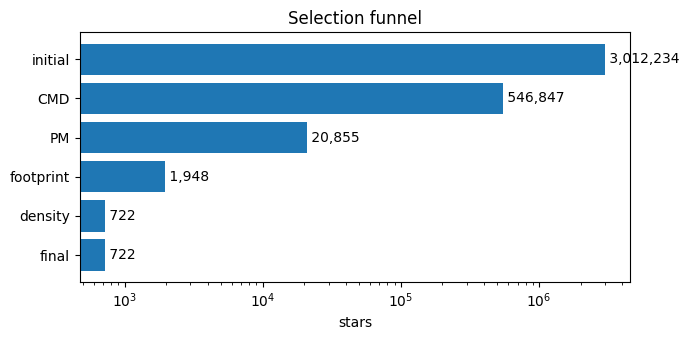

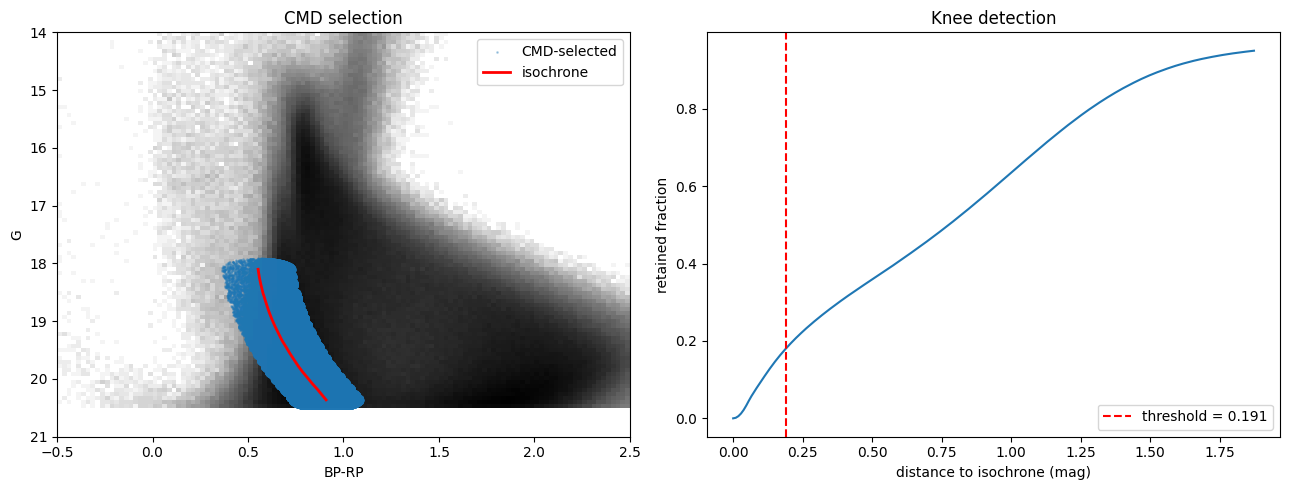

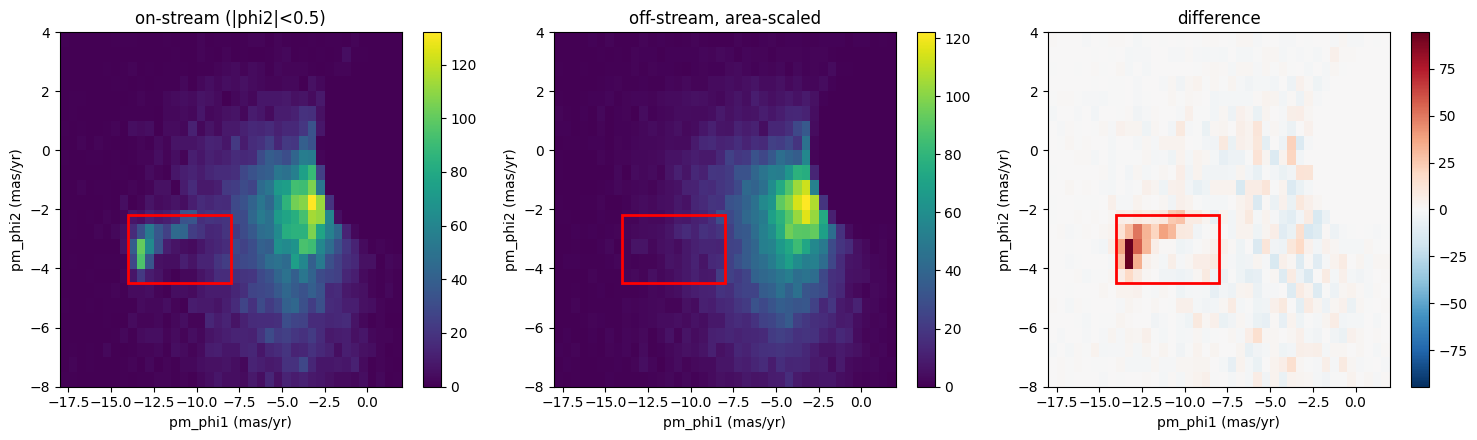

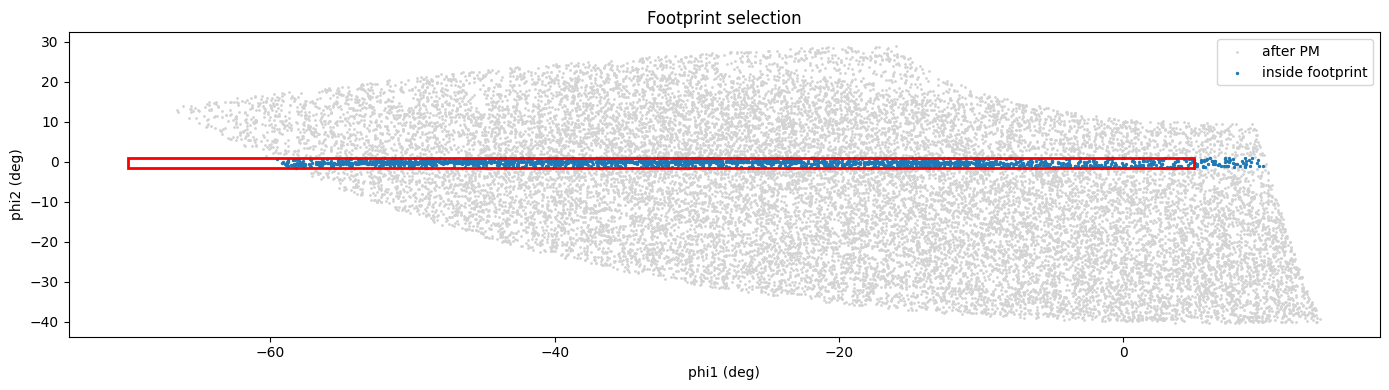

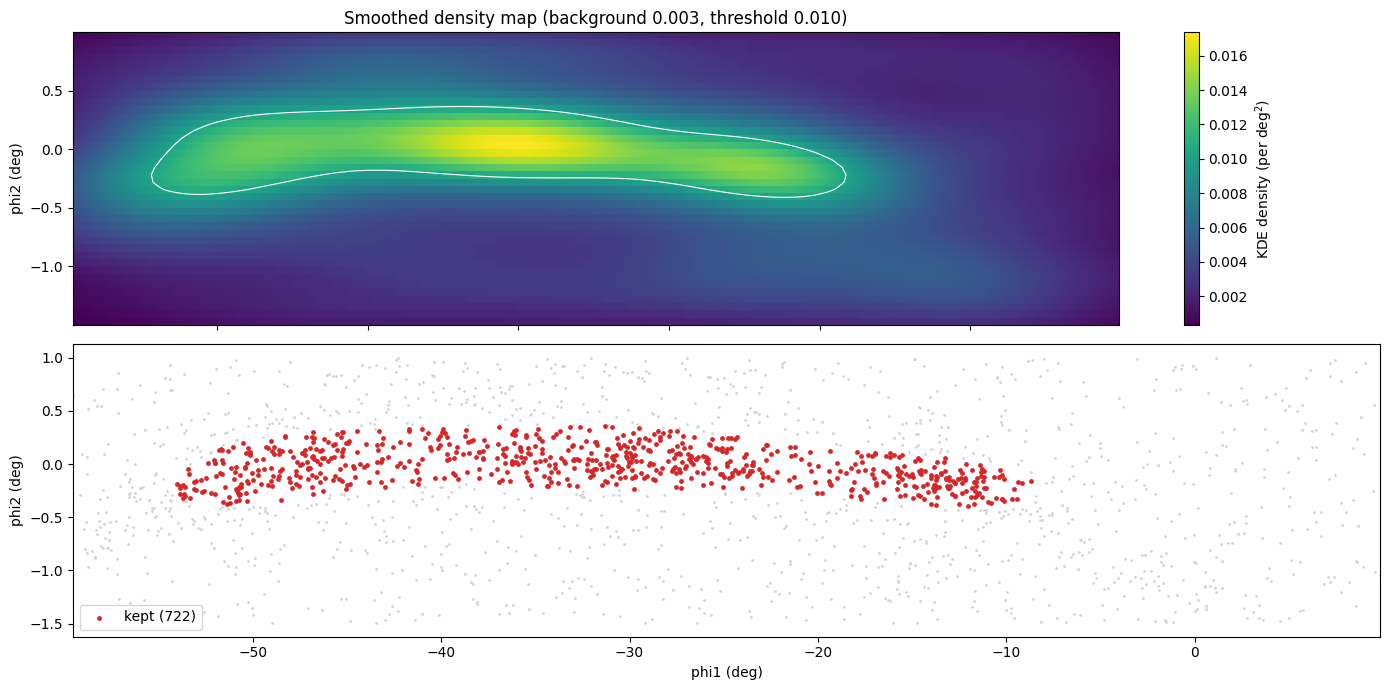

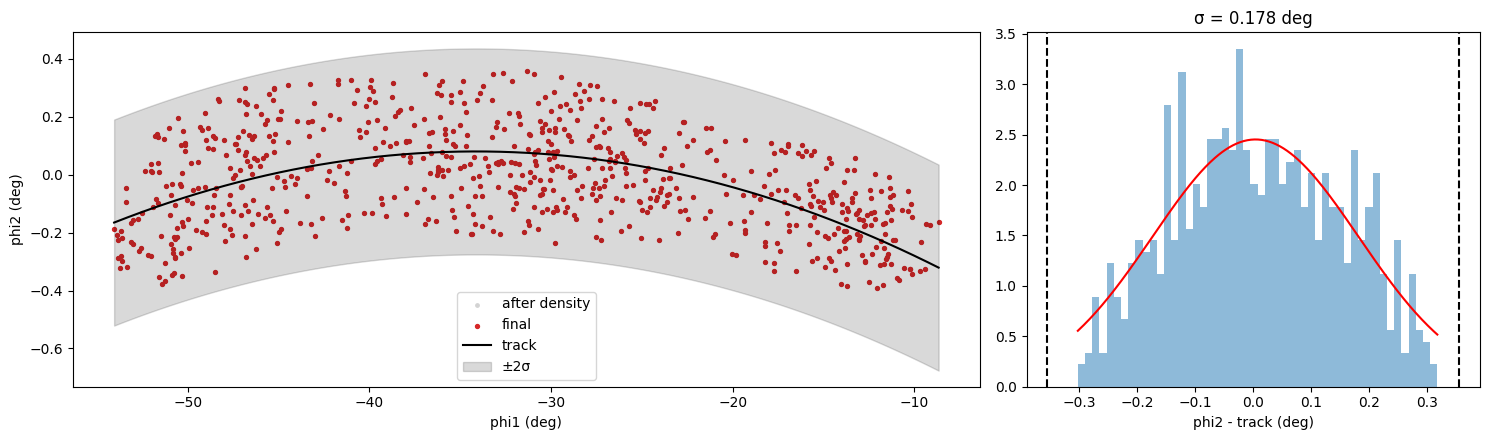

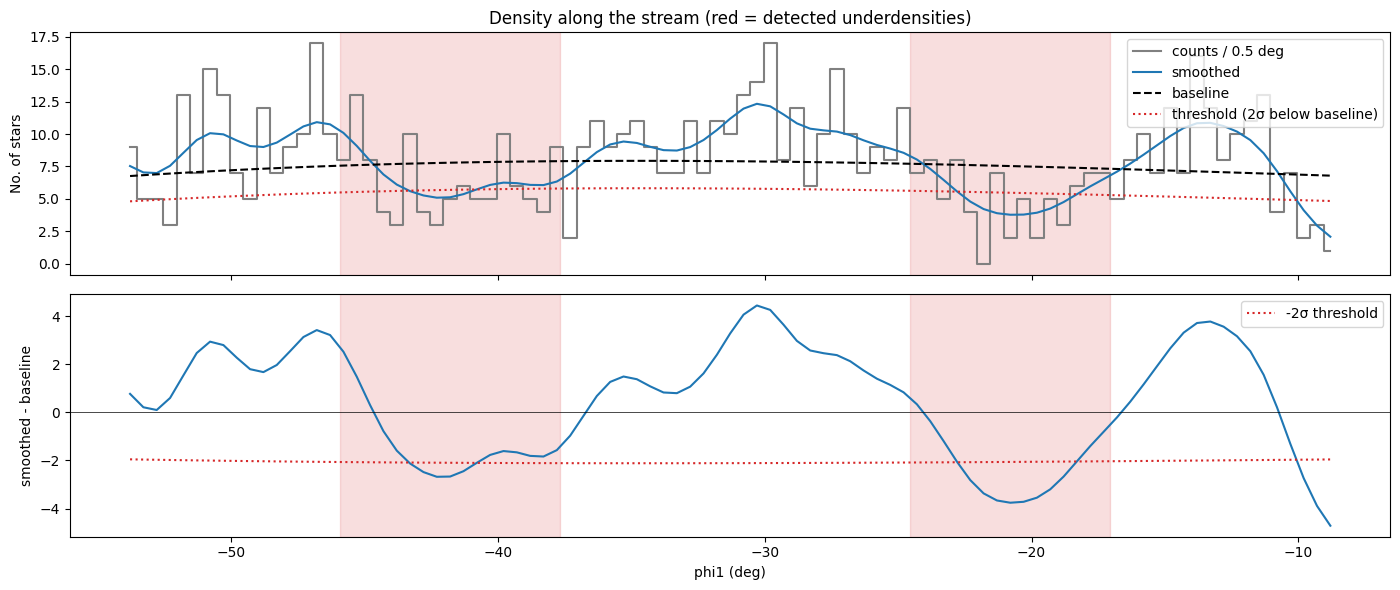

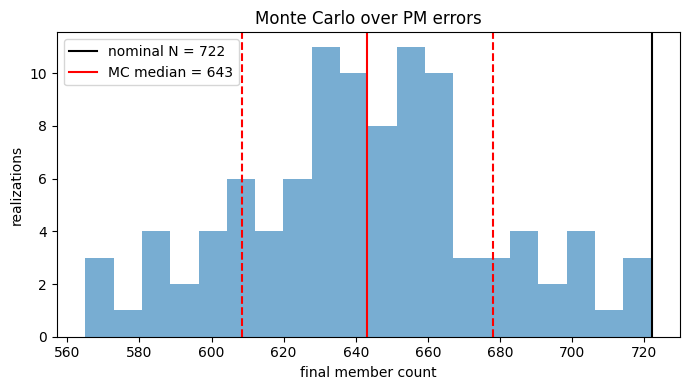

In [4]:
def main(isochrone_path: str | None = None,
         ra_edges=tuple(range(120, 221, 20)),
         dec_edges=tuple(range(20, 71, 10)),
         control_ra_shift: float = 10.0,
         n_mc: int = 100,
         min_significance = 2,
         background_multiple = 4,
         exclude_first_pct = 10.0,
         exclude_last_pct = 10.0,
         return_all = True,
         out_dir: str = "results"):
    """
    Analysing and searching for a stellar-stream over a grid of sky tiles in (RA, Dec).
    The sky is divided into rectangular tiles defined by `ra_edges` and
    `dec_edges`. Stars in each tile are filtered with an isochrone
    (colour-magnitude) selection, and the resulting signal is compared against
    a control field to judge whether a stream-like overdensity is present, to
    find its underdensities and their widths. We then run a Monte Carlo over
    the Gaia proper-motion errors (re-perturbing pmra/pmdec and rerunning the
    selection) to see how stable the selected membership and the detected
    underdensities are.
    """

    out_dir = Path(out_dir); out_dir.mkdir(exist_ok=True)
    iso = load_isochrone(isochrone_path)

    # 1. Data (cached, tiled, auto-split on truncation)
    raw = query_gaia_region_ra_dec(ra_edges=ra_edges, dec_edges=dec_edges)
    raw = raw.dropna(subset=["bp_rp", "g"])
    print(f"[1] Raw stars: {len(raw):,}")

    # 2. CMD cut
    after_cmd, dist_thresh = select_by_cmd(raw, iso)
    print(f"[2] After CMD: {len(after_cmd):,} (iso-distance threshold {dist_thresh:.3f})")

    # 3-6. PM -> footprint -> density -> track width
    res = apply_cuts(after_cmd, background_multiple = background_multiple)
    final, t = res["final"], res["track"]
    print(f"[3] After PM:        {len(res['pm']):,}")
    print(f"[4] After footprint: {len(res['footprint']):,}")
    print(f"[5] After density:   {len(res['density']):,}")
    print(f"[6] Final members:   {len(final):,}  "
          f"(sigma = {t['residual_sigma']:.3f} deg, 2-sigma cut = {t['suggested_width_2sigma']:.3f} deg)")

    # 7. Underdensities
    gap_kw = dict(min_significance=min_significance, bin_width=0.5,
                    exclude_first_pct=exclude_first_pct,
                    exclude_last_pct=exclude_last_pct)
    gaps = find_underdensities(final, **gap_kw)
    print(f"[7] Underdensities found: {len(gaps)}")
    if len(gaps):
        print(gaps.round(3).to_string(index=False))

    # 8. Monte Carlo over PM errors
    mc = mc_member_count(after_cmd, pipeline_fn=_safe_final,
                         background_multiple=background_multiple,
                         n_iterations=n_mc,
                         gap_fn=lambda f: find_underdensities(f, **gap_kw))
    print(f"[8] N = {mc['median']:.0f} "
          f"(+{mc['84th_pctile']-mc['median']:.0f} / -{mc['median']-mc['16th_pctile']:.0f}), "
          f"{mc['n_failed']} failed")
    rec = gap_recovery(gaps, mc)
    print(rec.round(3).to_string(index=False))

    result = PipelineResult(
        n_initial=len(raw), n_after_cmd=len(after_cmd),
        n_after_pm=len(res["pm"]), n_after_footprint=len(res["footprint"]),
        n_after_density=len(res["density"]), n_final=len(final),
        track_fit=t, underdensities=gaps,
        member_count_uncertainty=mc)

    final.to_pickle(out_dir / "gd1_members_polygon.pkl")
    gaps.to_csv(out_dir / "gd1_gaps_polygon.csv", index=False)

    diag = {
        "raw": raw,
        "iso": iso,
        "after_cmd": after_cmd,
        "dist_thresh": dist_thresh,
        "res": res,
        "gaps": gaps,
        "gap_kw": gap_kw,
        "mc": mc,
    }

    make_diagnostic_plots(result, diag)

    return result, final, diag


result, members, diag = main()